# Industry Project: Design a Real-Time Payment Fraud Detection System (ML System Design Case Study)

> **Who is this notebook for?** Someone preparing for an **ML system design interview**, or a junior engineer who joins a project where "the model" is only one box in a big diagram.
> You do not need to have read the other notebooks in this folder. Every number in this notebook is **computed in code**, so you can change an assumption and see what happens. Almost every line is commented. Runs on a CPU in well under a minute.

---

### How this notebook is different from the others in this folder

| `01_hld_ml_systems` … `07_software_engineering_for_ml` | This notebook |
|---|---|
| Each notebook explains **one layer**: architecture patterns, API design, databases, vector DBs, feature stores, registries, testing | Puts all layers together for **one concrete system**, from the first question to the failure-mode table |
| Concepts and component catalogues | **Numbers**: QPS, storage, bandwidth, servers, latency budget, cache hit rate, p99 |
| Diagrams you read | A **simulation** of the online path that you can break (slow database, small cache, no timeout) |
| "Streaming is fresher than batch" | A measured answer: how much fraud does a **1-hour-stale** feature miss? |

---

### The scenario (as an interviewer would say it)

> *"Design the fraud detection system for **PayNova**, a payment processor. Every card payment must be approved or declined in real time. Today a rules engine catches some fraud; the company wants ML. Go."*

What the business cares about:
- **Fraud losses**: every fraudulent payment that is approved costs the full amount plus a chargeback fee.
- **False declines**: every good customer we decline is lost revenue and an angry customer (industry surveys often find false declines cost merchants *more* than fraud itself).
- **Speed**: the fraud check sits inside the card authorization, so it must answer in **< 100 ms at p99** (Stripe publicly describes Radar as deciding in under 100 ms).

### The interview framework we follow (also a good structure for a real design doc)

```
1. Clarify requirements ─► 2. Estimate scale ─► 3. API & data ─► 4. High-level architecture
                                                                           │
8. Checklist & trade-offs ◄─ 7. Failure modes ◄─ 6. Batch vs. streaming ◄─ 5. Deep dive: online path
                                                                              (latency budget + simulation)
```

### Table of Contents
1. Setup: imports and the assumptions config
2. Requirements: functional and non-functional
3. Back-of-the-envelope capacity estimation (in code)
4. API contract and data model
5. High-level architecture
6. Latency budget per component
7. Simulating the online path: cache, timeouts, fallbacks, hedging (p50 / p99)
8. How many servers? Utilisation and queueing
9. Batch vs. streaming features: a measured trade-off
10. Failure modes and mitigations
11. Checking the design against the requirements (tests)
12. Interview checklist, summary, exercises and resources

---
## 1. Setup: imports and the assumptions config

In a design interview you **state your assumptions out loud** and write them down. In code, that means one config object: if the interviewer says "actually it is 10× bigger", you change one number and re-run everything.

In [1]:
# ---- Standard library ----
import logging
import math                                   # log / ceil for capacity math
import warnings
from collections import OrderedDict           # a tiny LRU cache for the simulation
from dataclasses import dataclass, asdict

# ---- Third-party ----
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_curve

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("fraud-design")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)


@dataclass(frozen=True)
class Assumptions:
    # --- traffic ---
    payments_per_day: float = 40e6        # 40 million card payments per day (a mid-size processor)
    peak_to_average: float = 3.0          # Black Friday / evening peaks vs. daily average
    headroom: float = 2.0                 # design for 2x the expected peak (growth + safety)
    # --- data sizes ---
    active_cards: float = 150e6           # cards seen in the last 12 months (feature store entities)
    features_per_card: int = 300          # aggregated features per card (counts, sums, ratios...)
    bytes_per_feature: int = 4            # float32
    store_overhead: float = 2.0           # keys, indexes, fragmentation in an in-memory store
    replication: int = 3                  # copies for availability
    request_bytes: int = 2_000            # JSON payment request
    response_bytes: int = 300             # decision + score + reasons
    event_log_bytes: int = 1_500          # what we store per payment for training/audit (incl. served features)
    retention_days: int = 2 * 365         # keep 2 years (chargebacks arrive up to ~120 days later; audits)
    # --- compute ---
    cpu_ms_per_request: float = 4.0       # parse + feature assembly + GBM model + rules, on one core
    target_utilisation: float = 0.5       # keep cores ~50% busy so queues stay short
    cores_per_pod: int = 4
    zones: int = 3                        # spread over 3 availability zones
    # --- service level objectives (SLOs) ---
    latency_p99_ms: float = 100.0
    availability: float = 0.9999          # "four nines"
    seed: int = 42


A = Assumptions()
rng = np.random.default_rng(A.seed)
print(pd.Series(asdict(A)).to_string())

payments_per_day      4.000000e+07
peak_to_average       3.000000e+00
headroom              2.000000e+00
active_cards          1.500000e+08
features_per_card     3.000000e+02
bytes_per_feature     4.000000e+00
store_overhead        2.000000e+00
replication           3.000000e+00
request_bytes         2.000000e+03
response_bytes        3.000000e+02
event_log_bytes       1.500000e+03
retention_days        7.300000e+02
cpu_ms_per_request    4.000000e+00
target_utilisation    5.000000e-01
cores_per_pod         4.000000e+00
zones                 3.000000e+00
latency_p99_ms        1.000000e+02
availability          9.999000e-01
seed                  4.200000e+01


---
## 2. Requirements: functional and non-functional

The first 5-10 minutes of an interview (and the first page of a design doc) are about **asking questions**. Typical clarifying questions and the answers we assume:

| Question | Assumed answer | Why it matters |
|---|---|---|
| Decision type? | Approve / decline / **step-up** (3-D Secure challenge) | A third option lowers false declines |
| Synchronous? | Yes, inside the authorization call | Hard latency limit; needs a fallback |
| When do we get labels? | Chargebacks arrive **days to months** later | Training data is always delayed; need proxy labels |
| Can we explain decisions? | Must return **reason codes** | Regulation, merchant disputes, analysts |
| Who else uses scores? | Fraud analysts (review queue), merchants (dashboard) | Extra read paths, but asynchronous |

**Functional requirements** (what the system does):
1. Score every payment and return `approve` / `review` / `decline` with a score and top reasons.
2. Use real-time behaviour (e.g. "5 payments on this card in the last 10 minutes").
3. Let analysts add **rules** without a model release (e.g. block a merchant during an attack).
4. Log every decision with the **exact features used** (for training, audits and debugging).
5. Retrain and safely deploy new models (shadow → canary → full).

**Non-functional requirements** (how well it does it):

In [2]:
requirements = pd.DataFrame([
    ("Latency", f"p99 <= {A.latency_p99_ms:.0f} ms for the whole fraud check", "inside card authorization"),
    ("Availability", f"{A.availability:.2%} (fail-safe: degrade, never block all payments)", "an outage = lost sales"),
    ("Throughput", "handle peak x headroom (computed below)", "Black Friday"),
    ("Freshness", "behavioural counters up to date within seconds", "card-testing attacks take minutes"),
    ("Quality", "catch >= 70% of fraud $ at <= 0.5% false declines", "business trade-off, agreed with finance"),
    ("Auditability", "every decision reproducible for 2 years", "disputes, regulators"),
    ("Privacy / security", "PCI-DSS: card numbers tokenised; no raw PAN in logs", "compliance"),
], columns=["requirement", "target", "why"])
requirements

,requirement,target,why
0,Latency,p99 <= 100 ms for the whole fraud check,inside card authorization
1,Availability,"99.99% (fail-safe: degrade, never block all payments)",an outage = lost sales
2,Throughput,handle peak x headroom (computed below),Black Friday
3,Freshness,behavioural counters up to date within seconds,card-testing attacks take minutes
4,Quality,catch >= 70% of fraud $ at <= 0.5% false declines,"business trade-off, agreed with finance"
5,Auditability,every decision reproducible for 2 years,"disputes, regulators"
6,Privacy / security,PCI-DSS: card numbers tokenised; no raw PAN in logs,compliance


---
## 3. Back-of-the-envelope capacity estimation (in code)

Interviewers expect rough numbers: **queries per second (QPS)**, **storage**, **bandwidth**, **servers**. The goal is the right *order of magnitude* (is it 10 servers or 1,000? 100 GB or 100 TB?), because that decides the architecture. A few constants to remember: 1 day ≈ 86,400 s ≈ 10^5 s; 1 KB × 1 million = 1 GB.

In [3]:
SECONDS_PER_DAY = 86_400


def human_bytes(n: float) -> str:
    """1536 -> '1.5 KB' (powers of 1000, which is what back-of-envelope math uses)."""
    for unit in ["B", "KB", "MB", "GB", "TB", "PB"]:
        if n < 1000:
            return f"{n:,.1f} {unit}"
        n /= 1000
    return f"{n:,.1f} EB"


def estimate_capacity(a: Assumptions) -> tuple[pd.DataFrame, dict]:
    """All capacity numbers in one place, with the formula next to each result."""
    avg_qps = a.payments_per_day / SECONDS_PER_DAY
    peak_qps = avg_qps * a.peak_to_average
    design_qps = peak_qps * a.headroom
    feature_store_raw = a.active_cards * a.features_per_card * a.bytes_per_feature
    feature_store_total = feature_store_raw * a.store_overhead * a.replication
    log_per_day = a.payments_per_day * a.event_log_bytes
    log_total = log_per_day * a.retention_days * a.replication
    bw_in = design_qps * a.request_bytes
    bw_out = design_qps * a.response_bytes
    feature_reads = design_qps * a.features_per_card * a.bytes_per_feature * 3   # card + merchant + device entities
    cores = design_qps * a.cpu_ms_per_request / 1000 / a.target_utilisation
    pods = math.ceil(cores / a.cores_per_pod)
    pods = math.ceil(pods / a.zones) * a.zones + a.zones                         # spread evenly + 1 spare per zone
    rows = [
        ("Average QPS", f"{avg_qps:,.0f}", "payments_per_day / 86,400"),
        ("Peak QPS", f"{peak_qps:,.0f}", "average x peak_to_average"),
        ("Design QPS", f"{design_qps:,.0f}", "peak x headroom"),
        ("Feature store (raw)", human_bytes(feature_store_raw), "cards x features x 4 bytes"),
        ("Feature store (total)", human_bytes(feature_store_total), "raw x overhead x replication"),
        ("Event log per day", human_bytes(log_per_day), "payments x bytes per event"),
        ("Event log total", human_bytes(log_total), "per day x retention x replication"),
        ("Inbound bandwidth", human_bytes(bw_in) + "/s", "design QPS x request size"),
        ("Outbound bandwidth", human_bytes(bw_out) + "/s", "design QPS x response size"),
        ("Feature reads", human_bytes(feature_reads) + "/s", "design QPS x 3 entities x 1.2 KB"),
        ("CPU cores (scoring)", f"{cores:,.0f}", "design QPS x CPU-ms / 1000 / utilisation"),
        ("Pods (4 cores)", f"{pods}", "cores / 4, spread over 3 zones + 1 spare each"),
    ]
    numbers = dict(avg_qps=avg_qps, peak_qps=peak_qps, design_qps=design_qps, cores=cores, pods=pods,
                   feature_store_total=feature_store_total, log_total=log_total)
    return pd.DataFrame(rows, columns=["quantity", "estimate", "formula"]), numbers


capacity_table, CAP = estimate_capacity(A)
capacity_table

,quantity,estimate,formula
0,Average QPS,463,"payments_per_day / 86,400"
1,Peak QPS,"1,389",average x peak_to_average
2,Design QPS,"2,778",peak x headroom
3,Feature store (raw),180.0 GB,cards x features x 4 bytes
4,Feature store (total),1.1 TB,raw x overhead x replication
5,Event log per day,60.0 GB,payments x bytes per event
6,Event log total,131.4 TB,per day x retention x replication
7,Inbound bandwidth,5.6 MB/s,design QPS x request size
8,Outbound bandwidth,833.3 KB/s,design QPS x response size
9,Feature reads,10.0 MB/s,design QPS x 3 entities x 1.2 KB


**What these numbers tell us about the architecture:**

- **~1,400 payments/second at peak** (design for ~2,800) is *moderate*: a stateless scoring service with a few dozen cores handles it. The hard part is not throughput, it is **latency** and **fresh features**.
- The feature store is **180 GB raw, ~1 TB with overhead and replication**: that fits in a distributed in-memory key-value store (Redis cluster, Aerospike, DynamoDB/Bigtable with a cache), not in the memory of one scoring pod. So every request needs a **network call** for features, which is why Section 7 exists.
- The event log grows to **more than 100 TB** over two years (with replication): it belongs in a data lake / warehouse (Parquet on object storage, BigQuery, Snowflake), not in the online database.
- Bandwidth is small (MB/s). In this system the network is not the bottleneck.

> 💡 **Interview tip:** say the numbers out loud with one sentence of *consequence* each ("hundreds of GB → distributed KV store → network hop → need a cache"). Numbers without consequences earn no points.

Let's see how sensitive the design is: what if the company signs a big merchant and traffic grows 10×?

In [4]:
scenarios = {"today": A,
             "10x traffic": Assumptions(payments_per_day=400e6, active_cards=600e6),
             "heavier model (20 CPU-ms)": Assumptions(cpu_ms_per_request=20.0)}
pd.DataFrame({name: {"design QPS": f"{c['design_qps']:,.0f}", "cores": f"{c['cores']:,.0f}", "pods": c["pods"],
                     "feature store": human_bytes(c["feature_store_total"]), "event log": human_bytes(c["log_total"])}
              for name, (_, c) in ((n, estimate_capacity(a)) for n, a in scenarios.items())})

,today,10x traffic,heavier model (20 CPU-ms)
design QPS,"2,778","27,778","2,778"
cores,22,222,111
pods,9,60,33
feature store,1.1 TB,4.3 TB,1.1 TB
event log,131.4 TB,1.3 PB,131.4 TB


Notice that a **5× heavier model** multiplies the scoring cores by 5, half of what **10× more traffic** costs, without a single extra customer. (The feature store and event log do not care about the model.) Model choice is a capacity decision, which is one reason fraud teams love gradient-boosted trees (fast on CPU) and why Stripe's engineering blog discusses training *and* serving speed when they changed model architectures.

---
## 4. API contract and data model

Agree on the interface early: other teams (checkout, analysts, merchants) build against it. The request contains **only what the payment gateway knows at that moment**; everything else (history) is looked up by the fraud service.

In [5]:
example_request = {
    "payment_id": "pay_8f2c91",            # idempotency key: retries must not double-count
    "timestamp": "2026-10-21T14:03:12.412Z",
    "card_token": "tok_4c1e...",            # tokenised card number (PCI-DSS: never the raw PAN)
    "amount": 129.90, "currency": "EUR",
    "merchant_id": "m_55120", "mcc": "5732",  # merchant category code (electronics)
    "device_id": "d_a81f", "ip_country": "DE", "card_country": "DE",
    "channel": "ecommerce",
}
example_response = {
    "payment_id": "pay_8f2c91",
    "decision": "review",                   # approve | review (3-D Secure step-up) | decline
    "score": 0.73,
    "reasons": ["5 payments on card in 10 min", "new device", "amount 4x card average"],
    "model_version": "fraud-gbm-2026-10-14", "rules_version": "r-1882",
    "degraded": False,                      # True if a fallback was used (feature store slow, model down...)
    "latency_ms": 23.4,
}
entities = pd.DataFrame([
    ("card", "card_token", "counts/sums over 10 min, 1 h, 24 h, 30 d; avg amount; countries seen", "streaming + batch"),
    ("merchant", "merchant_id", "fraud rate 30 d, chargeback rate, volume spike ratio", "batch (hourly)"),
    ("device", "device_id", "cards seen on device 24 h, first-seen date", "streaming"),
    ("payment event log", "payment_id", "request + served features + decision + later label", "append-only, lake"),
], columns=["entity", "key", "example features", "updated by"])
print("Request :", example_request)
print("Response:", example_response)
entities

Request : {'payment_id': 'pay_8f2c91', 'timestamp': '2026-10-21T14:03:12.412Z', 'card_token': 'tok_4c1e...', 'amount': 129.9, 'currency': 'EUR', 'merchant_id': 'm_55120', 'mcc': '5732', 'device_id': 'd_a81f', 'ip_country': 'DE', 'card_country': 'DE', 'channel': 'ecommerce'}
Response: {'payment_id': 'pay_8f2c91', 'decision': 'review', 'score': 0.73, 'reasons': ['5 payments on card in 10 min', 'new device', 'amount 4x card average'], 'model_version': 'fraud-gbm-2026-10-14', 'rules_version': 'r-1882', 'degraded': False, 'latency_ms': 23.4}


,entity,key,example features,updated by
0,card,card_token,"counts/sums over 10 min, 1 h, 24 h, 30 d; avg amount; countries seen",streaming + batch
1,merchant,merchant_id,"fraud rate 30 d, chargeback rate, volume spike ratio",batch (hourly)
2,device,device_id,"cards seen on device 24 h, first-seen date",streaming
3,payment event log,payment_id,request + served features + decision + later label,"append-only, lake"


Two details interviewers love:
- **`payment_id` as idempotency key**: the gateway retries on timeouts; the counters must not count the same payment twice.
- **`degraded` flag + versions in every response**: when something goes wrong you can later tell *which* decisions were made in fallback mode and by *which* model.

---
## 5. High-level architecture

Two paths, as in most real-time ML systems:
- **Online path** (synchronous, milliseconds): gateway → fraud service → feature lookup → model → rules → decision.
- **Async / offline paths** (seconds to days): stream processing updates counters; the event log feeds training; labels (chargebacks) arrive later; the model registry ships new versions.

Below is the diagram drawn with matplotlib (the same picture as a **Mermaid** block, which renders on GitHub and in most design-doc tools, is in the next markdown cell).

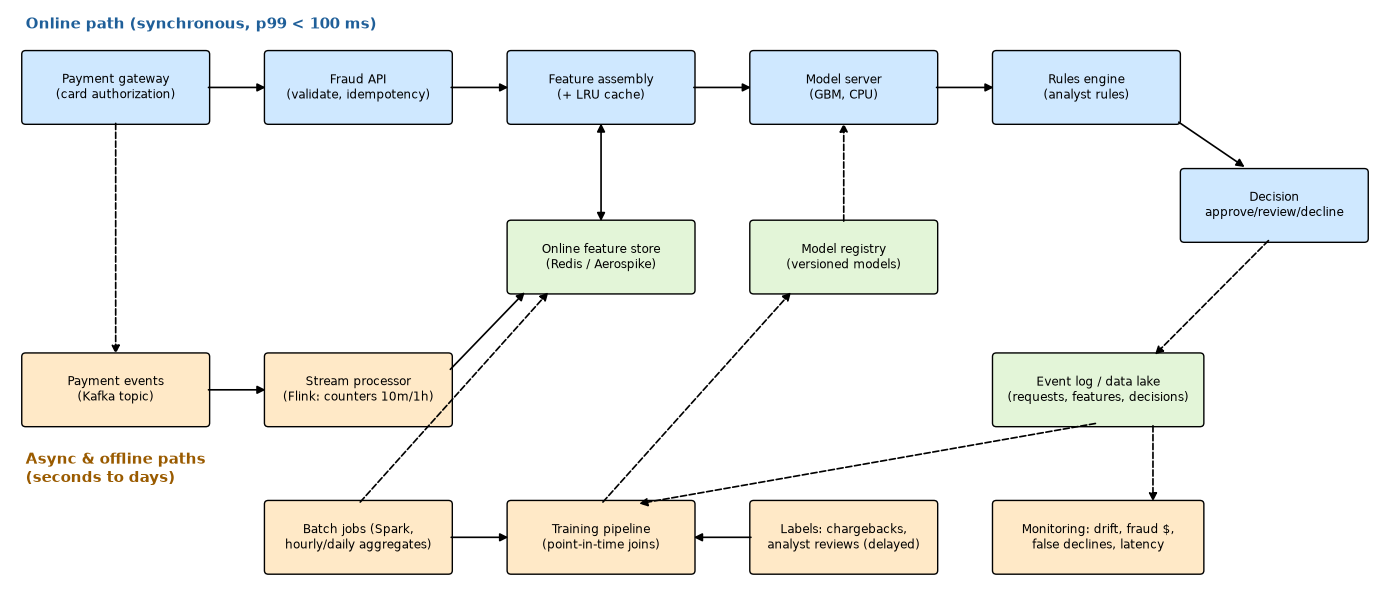

In [6]:
def box(ax, xy, text, color, w=2.3, h=0.9):
    """Draw a rounded box with centred text."""
    ax.add_patch(FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.05", fc=color, ec="black", lw=1))
    ax.text(xy[0] + w / 2, xy[1] + h / 2, text, ha="center", va="center", fontsize=8.5)


def arrow(ax, start, end, style="-|>", color="black", ls="-"):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle=style, mutation_scale=12, color=color, ls=ls, lw=1.2))


ONLINE, ASYNC, STORE = "#cfe8ff", "#ffe9c7", "#e3f5d8"
fig, ax = plt.subplots(figsize=(14, 6.2))
ax.set_xlim(0, 17.5); ax.set_ylim(0, 8); ax.axis("off")
# online path (top row)
box(ax, (0.2, 6.5), "Payment gateway\n(card authorization)", ONLINE)
box(ax, (3.3, 6.5), "Fraud API\n(validate, idempotency)", ONLINE)
box(ax, (6.4, 6.5), "Feature assembly\n(+ LRU cache)", ONLINE)
box(ax, (9.5, 6.5), "Model server\n(GBM, CPU)", ONLINE)
box(ax, (12.6, 6.5), "Rules engine\n(analyst rules)", ONLINE)
box(ax, (15.0, 4.9), "Decision\napprove/review/decline", ONLINE, w=2.3)
for x0, x1 in [(2.5, 3.3), (5.6, 6.4), (8.7, 9.5), (11.8, 12.6)]:
    arrow(ax, (x0, 6.95), (x1, 6.95))
arrow(ax, (14.9, 6.5), (15.8, 5.85))
# stores (middle row)
box(ax, (6.4, 4.2), "Online feature store\n(Redis / Aerospike)", STORE)
box(ax, (9.5, 4.2), "Model registry\n(versioned models)", STORE)
box(ax, (12.6, 2.4), "Event log / data lake\n(requests, features, decisions)", STORE, w=2.6)
arrow(ax, (7.55, 6.5), (7.55, 5.1), style="<|-|>")
arrow(ax, (10.65, 5.1), (10.65, 6.5), ls="--")
arrow(ax, (16.1, 4.9), (14.6, 3.3), ls="--")
# async / offline paths (bottom)
box(ax, (0.2, 2.4), "Payment events\n(Kafka topic)", ASYNC)
box(ax, (3.3, 2.4), "Stream processor\n(Flink: counters 10m/1h)", ASYNC)
box(ax, (3.3, 0.4), "Batch jobs (Spark,\nhourly/daily aggregates)", ASYNC)
box(ax, (6.4, 0.4), "Training pipeline\n(point-in-time joins)", ASYNC)
box(ax, (9.5, 0.4), "Labels: chargebacks,\nanalyst reviews (delayed)", ASYNC)
box(ax, (12.6, 0.4), "Monitoring: drift, fraud $,\nfalse declines, latency", ASYNC, w=2.6)
arrow(ax, (1.35, 6.5), (1.35, 3.3), ls="--")
arrow(ax, (2.5, 2.85), (3.3, 2.85))
arrow(ax, (5.6, 3.1), (6.6, 4.2))
arrow(ax, (5.6, 0.85), (6.4, 0.85))
arrow(ax, (4.45, 1.3), (6.9, 4.2), ls="--")
arrow(ax, (13.9, 2.4), (8.0, 1.3), ls="--")
arrow(ax, (9.5, 0.85), (8.7, 0.85))
arrow(ax, (7.55, 1.3), (10.0, 4.2), ls="--")
ax.text(0.2, 7.75, "Online path (synchronous, p99 < 100 ms)", fontsize=11, fontweight="bold", color="#1f5f99")
ax.text(0.2, 1.6, "Async & offline paths\n(seconds to days)", fontsize=11, fontweight="bold", color="#9a5b00")
arrow(ax, (14.6, 2.4), (14.6, 1.3), ls="--")                       # event log feeds monitoring
plt.tight_layout(); plt.show()

The same architecture as a Mermaid diagram (paste into a GitHub README or design doc):

```mermaid
flowchart LR
  GW[Payment gateway] --> API[Fraud API]
  API --> FA[Feature assembly + LRU cache]
  FA <--> FS[(Online feature store)]
  FA --> M[Model server]
  M --> R[Rules engine] --> D{approve / review / decline}
  GW -. events .-> K[[Kafka]] --> SP[Stream processor] --> FS
  B[Batch jobs] --> FS
  D -. log .-> L[(Event log / lake)] --> TP[Training pipeline]
  LB[Delayed labels: chargebacks] --> TP --> REG[(Model registry)] -. deploy .-> M
  L --> MON[Monitoring]
```

**Why a rules engine *after* the model?** Analysts must be able to react to a new attack within minutes ("decline all payments from merchant X over €500"), while a model retrain takes days. Rules are also the **fallback** when the model is unavailable.

---
## 6. Latency budget per component

"p99 < 100 ms" is a promise for the *whole* path. A **latency budget** splits it into per-component targets, so each team knows its limit. Tips used in practice:
- Leave generous **slack** (here 40%) for things you forgot (retries, GC pauses, a slow network day, the next feature someone wants to add).
- Logging to the event log is done **asynchronously** (fire-and-forget to Kafka), so it costs ~0 ms on the critical path.
- Adding p99s is pessimistic (they rarely all happen at once), which is exactly why it is safe for a budget.

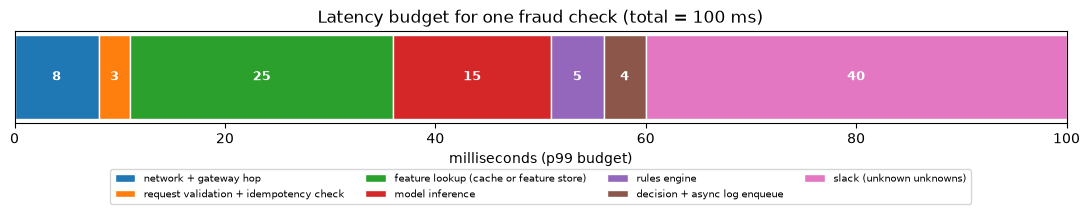

,component,budget_p99_ms,share
0,network + gateway hop,8.0,8%
1,request validation + idempotency check,3.0,3%
2,feature lookup (cache or feature store),25.0,25%
3,model inference,15.0,15%
4,rules engine,5.0,5%
5,decision + async log enqueue,4.0,4%
6,slack (unknown unknowns),40.0,40%


In [7]:
latency_budget = pd.DataFrame([
    ("network + gateway hop", 8), ("request validation + idempotency check", 3),
    ("feature lookup (cache or feature store)", 25), ("model inference", 15),
    ("rules engine", 5), ("decision + async log enqueue", 4),
], columns=["component", "budget_p99_ms"])
latency_budget.loc[len(latency_budget)] = ("slack (unknown unknowns)", A.latency_p99_ms - latency_budget["budget_p99_ms"].sum())
latency_budget["share"] = (latency_budget["budget_p99_ms"] / A.latency_p99_ms).map("{:.0%}".format)

fig, ax = plt.subplots(figsize=(11, 2.8))
left = 0
for (comp, ms, _), color in zip(latency_budget.itertuples(index=False), plt.cm.tab10.colors):
    ax.barh(0, ms, left=left, color=color, edgecolor="white")
    ax.text(left + ms / 2, 0, f"{ms:.0f}", ha="center", va="center", fontsize=9, color="white", fontweight="bold")
    left += ms
ax.set_xlim(0, A.latency_p99_ms); ax.set_yticks([]); ax.set_xlabel("milliseconds (p99 budget)")
ax.legend(latency_budget["component"], ncol=4, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.45))
ax.set_title("Latency budget for one fraud check (total = 100 ms)")
plt.tight_layout(); plt.show()
latency_budget

---
## 7. Simulating the online path: cache, timeouts, fallbacks, hedging (p50 / p99)

Averages hide the pain: a payment system cares about the **slowest 1%** (p99) and even the slowest 0.1% (p99.9), because at 1,400 payments/s, "1 in 1,000" happens more than once per second. Jeff Dean and Luiz Barroso's paper *"The Tail at Scale"* explains why tails dominate in distributed systems.

We simulate the feature lookup + model with realistic latency distributions:
- **Feature store**: usually ~4 ms, but ~1.5% of calls hit a slow node (GC pause, hot partition) and take 40-250 ms. That rare tail is what breaks p99.
- **Card popularity is skewed** (a Zipf distribution): some cards pay many times a day, most rarely. That skew is why a **small cache** helps.

Then we add the standard mitigations one at a time:
1. **LRU cache** in the scoring pod for slowly-changing features (profile, merchant stats). Real-time counters still come from the store or a short-TTL cache, because a stale counter is wrong in fraud.
2. **Timeout + fallback**: if features take > 25 ms, stop waiting and score with **default/stale features + rules** (flag `degraded=True`). Better a slightly worse decision than a payment timeout.
3. **Hedged request** (from "The Tail at Scale"): if the store has not answered after 10 ms, send a second request to another replica and use whichever answers first.

In [8]:
N_CARDS_SIM = 200_000                 # cards in the simulation (scaled down from 150M)
N_REQUESTS = 60_000                   # simulated payments


def zipf_card_ids(n_requests: int, n_cards: int, s: float, seed: int) -> np.ndarray:
    """Card ids with Zipf popularity: card k is chosen with probability proportional to 1/k^s."""
    r = np.random.default_rng(seed)
    weights = 1.0 / np.arange(1, n_cards + 1) ** s
    return r.choice(n_cards, size=n_requests, p=weights / weights.sum())


def store_latency(r, size=None):
    """Feature-store latency in ms: lognormal around 4 ms, with a 1.5% slow tail of 40-250 ms."""
    base = r.lognormal(mean=np.log(4.0), sigma=0.45, size=size)
    slow = r.random(size) < 0.015
    return base + slow * r.uniform(40, 250, size=size)


def simulate_online_path(card_ids, cache_size=0, timeout_ms=None, hedge_after_ms=None, seed=0) -> dict:
    """Latency of the fraud check for every request under one configuration."""
    r = np.random.default_rng(seed)
    cache = OrderedDict()                                   # LRU cache: most recently used at the end
    n = len(card_ids)
    network = r.lognormal(np.log(3.0), 0.3, n)              # gateway <-> fraud service hops
    validation = r.lognormal(np.log(0.8), 0.3, n)
    model = r.lognormal(np.log(3.0), 0.25, n) + (r.random(n) < 0.005) * 15   # rare slow model call
    rules = r.lognormal(np.log(0.5), 0.3, n)
    primary, backup = store_latency(r, n), store_latency(r, n)
    fetch = np.empty(n); hits = np.zeros(n, bool); degraded = np.zeros(n, bool)
    for i, card in enumerate(card_ids):
        if cache_size and card in cache:                    # cache hit: ~0.2 ms in-process lookup
            cache.move_to_end(card)
            fetch[i], hits[i] = 0.2, True
            continue
        t = primary[i]
        if hedge_after_ms is not None and t > hedge_after_ms:
            t = min(t, hedge_after_ms + backup[i])          # second request to another replica, first answer wins
        if timeout_ms is not None and t > timeout_ms:
            t, degraded[i] = timeout_ms, True               # give up waiting: fallback features + rules
        fetch[i] = t
        if cache_size and not degraded[i]:
            cache[card] = True                              # store in cache, evict least recently used if full
            if len(cache) > cache_size:
                cache.popitem(last=False)
    total = network + validation + fetch + model + rules
    hedged = (~hits) & (primary > hedge_after_ms) if hedge_after_ms is not None else np.zeros(n, bool)
    return {"total": total, "fetch": fetch, "hits": hits, "hit_rate": hits.mean(), "degraded_rate": degraded.mean(),
            "extra_store_calls": hedged.mean()}                    # hedging = extra load on the feature store


def summarize(name: str, res: dict) -> dict:
    t = res["total"]
    return {"configuration": name, "p50_ms": np.percentile(t, 50), "p95_ms": np.percentile(t, 95),
            "p99_ms": np.percentile(t, 99), "p99.9_ms": np.percentile(t, 99.9), "max_ms": t.max(),
            "cache_hit_rate": res["hit_rate"], "degraded_rate": res["degraded_rate"],
            "extra_store_calls": res["extra_store_calls"]}


card_ids = zipf_card_ids(N_REQUESTS, N_CARDS_SIM, s=1.05, seed=A.seed)
CACHE = int(0.05 * N_CARDS_SIM)                             # cache 5% of cards in each pod
configs = {
    "1. direct feature store": dict(),
    "2. + LRU cache (5% of cards)": dict(cache_size=CACHE),
    "3. + cache + 25 ms timeout/fallback": dict(cache_size=CACHE, timeout_ms=25),
    "4. + cache + hedge@10ms + timeout": dict(cache_size=CACHE, timeout_ms=25, hedge_after_ms=10),
}
sim = {name: simulate_online_path(card_ids, seed=1, **kw) for name, kw in configs.items()}
sim_table = pd.DataFrame([summarize(n, r) for n, r in sim.items()]).set_index("configuration")
sim_table.round({"p50_ms": 1, "p95_ms": 1, "p99_ms": 1, "p99.9_ms": 1, "max_ms": 0, "cache_hit_rate": 3, "degraded_rate": 4, "extra_store_calls": 4})

,p50_ms,p95_ms,p99_ms,p99.9_ms,max_ms,cache_hit_rate,degraded_rate,extra_store_calls
configuration,,,,,,,,
1. direct feature store,11.7,17.4,124.6,250.7,264.0,0.000,0.0000,0.0000
2. + LRU cache (5% of cards),8.3,14.4,21.5,222.3,261.0,0.717,0.0000,0.0000
3. + cache + 25 ms timeout/fallback,8.3,14.4,21.5,33.5,47.0,0.716,0.0045,0.0000
4. + cache + hedge@10ms + timeout,8.3,14.4,20.4,26.6,36.0,0.717,0.0001,0.0106


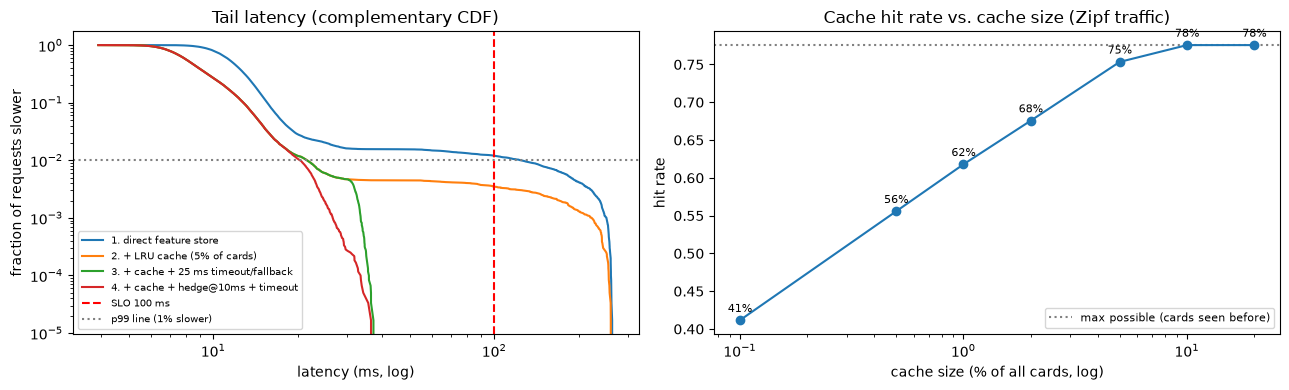

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, res in sim.items():
    t = np.sort(res["total"])
    tail = 1 - np.arange(1, len(t) + 1) / len(t)                     # fraction of requests slower than t
    axes[0].plot(t, tail, label=name)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].axvline(A.latency_p99_ms, color="red", ls="--", label="SLO 100 ms")
axes[0].axhline(0.01, color="grey", ls=":", label="p99 line (1% slower)")
axes[0].set(xlabel="latency (ms, log)", ylabel="fraction of requests slower", title="Tail latency (complementary CDF)")
axes[0].legend(fontsize=7.5)

# How big must the cache be? Hit rate vs. cache size, measured on the 2nd half (warm cache)
fractions = [0.001, 0.005, 0.01, 0.02, 0.05, 0.10, 0.20]
hit_rates = [simulate_online_path(card_ids, cache_size=int(f * N_CARDS_SIM), seed=2)["hits"][N_REQUESTS // 2:].mean()
             for f in fractions]
first_time = 1 - len(set(card_ids[N_REQUESTS // 2:]) - set(card_ids[:N_REQUESTS // 2])) / (N_REQUESTS // 2)
axes[1].axhline(first_time, color="grey", ls=":", label="max possible (cards seen before)")
axes[1].legend(fontsize=8)
axes[1].plot([f * 100 for f in fractions], hit_rates, marker="o")
axes[1].set_xscale("log")
axes[1].set(xlabel="cache size (% of all cards, log)", ylabel="hit rate", title="Cache hit rate vs. cache size (Zipf traffic)")
for f, h in zip(fractions, hit_rates):
    axes[1].annotate(f"{h:.0%}", (f * 100, h), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
plt.tight_layout(); plt.show()

**What the simulation shows** (compare the rows of the table above):

- **Direct feature store**: the median is fine, but the rare slow calls push the tail (p99 / p99.9) far above the median, close to or beyond the 100 ms SLO. The median tells you nothing about this.
- **The cache** answers a large share of requests in-process (see `cache_hit_rate`), so fewer requests ever *meet* a slow node. The tail improves, but it does not disappear: a cache miss can still be slow.
- **Timeout + fallback** puts a hard ceiling on the tail: no request waits longer than 25 ms for features. The price is the `degraded_rate`: those payments are scored with fallback features, so you must *monitor* that rate and know how much worse degraded decisions are.
- **Hedging** rescues most slow calls before the timeout, so the degraded rate drops sharply. The price is extra load on the feature store, but only for requests slower than 10 ms, about 1% of all requests here (`extra_store_calls`). That is why hedging after a delay is much cheaper than "always send two requests".
- The right plot shows the **diminishing returns** of a bigger cache with skewed traffic: caching just 1% of the cards already gives most of the achievable hit rate (compare the 1% point with the plateau), and beyond ~5-10% nothing improves. The curve flattens below 100% because many payments come from cards that were never seen before in this window (the grey line): no cache can help a first visit (a *compulsory miss*). In the interview, this justifies "a small per-pod cache" instead of "cache everything".

---
## 8. How many servers? Utilisation and queueing

Section 3 used **50% target utilisation**. Why not run servers at 90% to save money? Because waiting time explodes as a server gets busy. For the simplest queue model (M/M/1: random arrivals, one server), the response time is exponential with rate (μ − λ), so

$$ p99 = \frac{\ln(100)}{\mu - \lambda} = \frac{4.6 \cdot S}{1 - \rho} $$

where *S* is the service time and *ρ* the utilisation. The p99 doubles from 50% to 75% busy, and grows 5× from 50% to 90%.

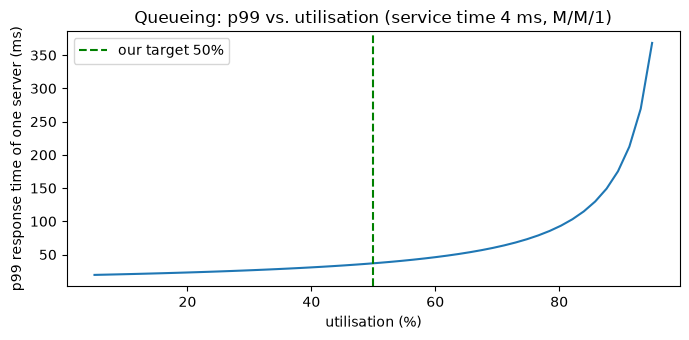

utilisation 50%: p99 ≈  36.8 ms
utilisation 75%: p99 ≈  73.7 ms
utilisation 90%: p99 ≈ 184.2 ms


In [10]:
service_ms = A.cpu_ms_per_request
rho = np.linspace(0.05, 0.95, 50)
p99_queue = np.log(100) * service_ms / (1 - rho)                     # M/M/1 p99 response time

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(rho * 100, p99_queue)
ax.axvline(A.target_utilisation * 100, color="green", ls="--", label=f"our target {A.target_utilisation:.0%}")
ax.set(xlabel="utilisation (%)", ylabel="p99 response time of one server (ms)",
       title=f"Queueing: p99 vs. utilisation (service time {service_ms:.0f} ms, M/M/1)")
ax.legend(); plt.tight_layout(); plt.show()
for u in [0.5, 0.75, 0.9]:
    print(f"utilisation {u:.0%}: p99 ≈ {np.log(100) * service_ms / (1 - u):5.1f} ms")

Real servers have several cores (M/M/c queues behave better than M/M/1), but the shape is the same: **leave headroom**. That headroom is also what absorbs a zone failure: with 3 zones, losing one moves its traffic to the other two, so each must be able to run at 1.5× normal load.

---
## 9. Batch vs. streaming features: a measured trade-off

A classic interview question: *"Do you need streaming, or are batch features enough?"* Streaming (Kafka + Flink) gives fresh counters but is more complex and expensive to run; batch (Spark/SQL every hour or day) is simple but stale.

Instead of arguing, we **measure** it on simulated card payments with a typical fraud pattern: a stolen card is used in a **burst** (small "card-testing" payments, then larger ones) within minutes. Some honest customers also have shopping sprees, so bursts alone are not proof of fraud.

The feature `payments in the last hour` is computed in three ways:

| Version | How it is computed at scoring time | Staleness |
|---|---|---|
| streaming | exact count up to the current payment | seconds |
| hourly batch | count as of the last full hour (job runs every hour) | up to 60 min |
| daily batch | count as of last midnight | up to 24 h |

All features are **point-in-time correct** (computed only from payments *before* the scored one): this is how a feature store builds training data without leakage.

In [11]:
def simulate_payments(n_cards: int = 15_000, days: int = 4, seed: int = 7) -> pd.DataFrame:
    """Card payments with fraud bursts and honest shopping sprees. Time in seconds."""
    r = np.random.default_rng(seed)
    horizon = days * SECONDS_PER_DAY
    rows = []
    for card in range(n_cards):
        n_legit = r.poisson(1.6 * days)                                   # ~1.6 honest payments per day
        t = np.sort(r.uniform(0, horizon, n_legit))
        rows.append(np.c_[np.full(n_legit, card), t, r.lognormal(3.4, 0.9, n_legit), np.zeros(n_legit)])
        if r.random() < 0.08:                                             # 8% of cards: honest shopping spree
            k = r.integers(3, 8)
            ts = r.uniform(0, horizon) + np.cumsum(r.exponential(600, k))   # every ~10 min
            rows.append(np.c_[np.full(k, card), ts, r.lognormal(3.9, 1.0, k), np.zeros(k)])
        if r.random() < 0.02:                                             # 2% of cards get stolen
            k = r.integers(2, 12) if r.random() < 0.7 else 1              # 30% of frauds are a single payment
            ts = r.uniform(0, horizon) + np.cumsum(r.exponential(r.choice([150, 600]), k))  # every ~2.5 or ~10 min
            testing = r.random() < 0.6                                    # most start with tiny 'card-testing' payments
            amounts = np.where((np.arange(k) < 2) & testing, r.uniform(0.5, 5, k), r.lognormal(4.8, 0.9, k))
            rows.append(np.c_[np.full(k, card), ts, amounts, np.ones(k)])
    df = pd.DataFrame(np.vstack(rows), columns=["card", "t", "amount", "is_fraud"])
    df = df[df["t"] < horizon].sort_values(["card", "t"]).reset_index(drop=True)
    df["card"] = df["card"].astype(int); df["is_fraud"] = df["is_fraud"].astype(int)
    df["day"] = (df["t"] // SECONDS_PER_DAY).astype(int)
    df["hour_of_day"] = (df["t"] % SECONDS_PER_DAY) // 3600
    return df


payments = simulate_payments()
print(f"{len(payments):,} payments, {payments['card'].nunique():,} cards, fraud rate {payments['is_fraud'].mean():.2%}")
payments.groupby("day")["is_fraud"].agg(["size", "mean"]).rename(columns={"size": "payments", "mean": "fraud_rate"})

103,772 payments, 14,980 cards, fraud rate 1.45%


,payments,fraud_rate
day,,
0,25878,0.015612
1,26037,0.014287
2,25692,0.013506
3,26165,0.014561


In [12]:
def window_features(df: pd.DataFrame, as_of: np.ndarray, prefix: str) -> pd.DataFrame:
    """Count and sum of a card's payments in (as_of - window, as_of), using ONLY earlier payments.

    Vectorised trick: key = card * BIG + time, so one sorted array holds all cards and a
    binary search (np.searchsorted) never crosses into another card's payments.
    """
    BIG = 1e7                                                   # larger than the whole time range
    key = df["card"].to_numpy() * BIG + df["t"].to_numpy()     # sorted, because df is sorted by card, t
    q = df["card"].to_numpy() * BIG + as_of
    cum_amount = np.r_[0, np.cumsum(df["amount"].to_numpy())]
    right = np.minimum(np.searchsorted(key, q, side="left"), np.arange(len(df)))  # strictly before this payment
    out = {}
    for name, window in [("cnt_10m", 600), ("cnt_1h", 3600), ("cnt_24h", SECONDS_PER_DAY)]:
        left = np.searchsorted(key, q - window, side="left")
        out[f"{prefix}{name}"] = np.maximum(right - left, 0)
        if name == "cnt_1h":
            out[f"{prefix}sum_1h"] = np.where(right > left, cum_amount[right] - cum_amount[left], 0.0)
    return pd.DataFrame(out, index=df.index)


t = payments["t"].to_numpy()
fresh = window_features(payments, t, "")                                          # streaming: as of now
hourly = window_features(payments, np.floor(t / 3600) * 3600, "")                 # as of last full hour
daily = window_features(payments, np.floor(t / SECONDS_PER_DAY) * SECONDS_PER_DAY, "")   # as of midnight

BASE = ["amount", "hour_of_day"]                                                  # known at request time
FEATURES = BASE + list(fresh.columns)
example_card = payments.loc[payments["is_fraud"] == 1, "card"].iloc[3]
view = payments[payments["card"] == example_card][["t", "amount", "is_fraud"]].assign(
    minute=lambda d: (d["t"] / 60).round(1),
    cnt_1h_streaming=fresh["cnt_1h"], cnt_1h_hourly=hourly["cnt_1h"], cnt_1h_daily=daily["cnt_1h"])
print("One stolen card: the streaming counter climbs during the burst, the batch counters lag behind")
view.drop(columns="t").round(2).head(12)

One stolen card: the streaming counter climbs during the burst, the batch counters lag behind


,amount,is_fraud,minute,cnt_1h_streaming,cnt_1h_hourly,cnt_1h_daily
6,2.78,1,1169.5,0,0,0
7,4.42,1,1169.5,1,0,0
8,145.89,1,1178.6,2,0,0
9,80.08,1,1181.1,3,0,0
10,136.26,1,1184.6,4,0,0
11,41.74,1,1215.4,5,5,0
12,72.14,1,1229.4,6,5,0
13,101.84,1,1267.4,2,2,0
14,272.84,1,1284.9,2,2,0
15,340.60,1,1307.3,2,2,0


In [13]:
train_mask = payments["day"] < 3                                   # days 0-2 train, day 3 = "future" test
y = payments["is_fraud"].to_numpy()
FEATURE_SETS = {"streaming": fresh, "hourly batch": hourly, "daily batch": daily}


def make_X(feats: pd.DataFrame) -> pd.DataFrame:
    return pd.concat([payments[BASE], feats], axis=1)[FEATURES]


def recall_at_fpr(y_true, score, max_fpr=0.005) -> float:
    """Share of fraud caught when we may decline at most 0.5% of honest payments."""
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(np.interp(max_fpr, fpr, tpr))


def fraud_dollars_caught(y_true, score, amounts, max_fpr=0.005) -> float:
    legit_scores = score[y_true == 0]
    threshold = np.quantile(legit_scores, 1 - max_fpr)                # decline the top 0.5% of honest scores
    caught = (score >= threshold) & (y_true == 1)
    return float(amounts[caught].sum() / amounts[y_true == 1].sum())


rows = []
test_amounts = payments.loc[~train_mask, "amount"].to_numpy()
for train_name, serve_name in [("streaming", "streaming"), ("streaming", "hourly batch"),
                               ("hourly batch", "hourly batch"), ("daily batch", "daily batch")]:
    model = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=A.seed)
    model.fit(make_X(FEATURE_SETS[train_name])[train_mask], y[train_mask])
    score = model.predict_proba(make_X(FEATURE_SETS[serve_name])[~train_mask])[:, 1]
    rows.append({"trained on": train_name, "served with": serve_name,
                 "PR-AUC": average_precision_score(y[~train_mask], score),
                 "fraud caught @0.5% false declines": recall_at_fpr(y[~train_mask], score),
                 "fraud $ caught": fraud_dollars_caught(y[~train_mask], score, test_amounts)})
freshness = pd.DataFrame(rows).round(3)
freshness

,trained on,served with,PR-AUC,fraud caught @0.5% false declines,fraud $ caught
0,streaming,streaming,0.637,0.551,0.687
1,streaming,hourly batch,0.331,0.307,0.327
2,hourly batch,hourly batch,0.229,0.165,0.225
3,daily batch,daily batch,0.113,0.100,0.172


**Reading the table (row by row):**

1. **Streaming → streaming** is clearly the best: the counter sees the burst while it is happening. Even so, with only five features it lands just short of the "70% of fraud $" target from Section 2. A real system adds device, IP, merchant and network features; that is the natural next deep-dive in an interview.
2. **Trained on streaming, served with hourly batch** is the classic **training-serving skew**. Offline, this model was evaluated with fresh features and looked like row 1; in production it receives stale (usually lower) counts and catches only about half as much fraud. Nothing crashes and no error is logged: the decisions are just worse. Feature stores exist largely to prevent this (one feature definition, used for training *and* serving, and served values logged for comparison).
3. **Hourly batch, trained and served consistently**, is honest about what it can do: it misses bursts that start and end within the same hour.
4. **Daily batch** loses most of the behavioural signal: the burst is invisible until the next day, when the card is already blocked by the bank.

So for *this* use case, streaming features are worth their cost, at least for the short-window counters. Slow-moving features (merchant fraud rate over 30 days, card age) stay in batch. Mixing both is the standard design (often called **lambda-style** feature pipelines):

In [14]:
pd.DataFrame([
    ("Freshness", "seconds", "hours to a day"),
    ("Typical stack", "Kafka + Flink / Spark Structured Streaming, online store", "Airflow + Spark/SQL, warehouse"),
    ("Cost & complexity", "high: always-on jobs, state, exactly-once, backfills are hard", "low: re-runnable, easy to backfill"),
    ("Failure mode", "consumer lag → silently stale counters", "late job → stale features for hours"),
    ("Training data", "must log served values or replay events carefully", "point-in-time joins on snapshots"),
    ("Use in fraud", "velocity counters (10 min, 1 h), device/IP fan-out", "merchant risk, card history, 30-day aggregates"),
], columns=["aspect", "streaming features", "batch features"])

,aspect,streaming features,batch features
0,Freshness,seconds,hours to a day
1,Typical stack,"Kafka + Flink / Spark Structured Streaming, online store","Airflow + Spark/SQL, warehouse"
2,Cost & complexity,"high: always-on jobs, state, exactly-once, backfills are hard","low: re-runnable, easy to backfill"
3,Failure mode,consumer lag → silently stale counters,late job → stale features for hours
4,Training data,must log served values or replay events carefully,point-in-time joins on snapshots
5,Use in fraud,"velocity counters (10 min, 1 h), device/IP fan-out","merchant risk, card history, 30-day aggregates"


---
## 10. Failure modes and mitigations

A senior answer always covers *"what breaks, and what happens then?"* The golden rule for fraud: **fail safe, not fail closed**. If the fraud system is down, approving low-risk payments with rules is better than declining every payment in the country.

In [15]:
failure_modes = pd.DataFrame([
    ("Feature store slow / down", "timeouts, p99 breach", "timeout + default/cached features + rules, degraded flag; hedged reads", "degraded_rate, store p99"),
    ("Model server down or bad deploy", "errors or crazy scores", "rules-only fallback; shadow → canary → auto-rollback on score drift", "error rate, score distribution"),
    ("Streaming job lag", "stale velocity counters (silent!)", "alert on consumer lag; switch to batch-feature model variant", "Kafka consumer lag, feature age"),
    ("New fraud pattern (adaptive attackers)", "fraud $ rises, model blind", "analyst rules within minutes; retrain; red-team the model", "fraud $ by segment, review-queue hit rate"),
    ("Delayed labels (chargebacks 30-120 days)", "slow feedback, can't evaluate quickly", "proxy labels (analyst reviews, 3-DS failures); label-delay-aware evaluation", "label coverage by age"),
    ("Feedback loop: declined payments get no label", "model learns only from what it approved", "small random 'exploration' holdout of approvals; counterfactual evaluation", "holdout fraud rate"),
    ("Training-serving skew", "offline metrics good, online bad", "single feature definitions (feature store), log served features, compare online/offline", "feature value drift online vs. offline"),
    ("Region / zone outage", "partial unavailability", "multi-zone deployment with headroom (Section 8), active-active regions", "availability SLO, error budget"),
    ("Retry storm / duplicate requests", "counters double-count", "idempotency key (payment_id), retry budgets with backoff", "duplicate rate"),
], columns=["failure", "symptom", "mitigation", "monitor"])
failure_modes

,failure,symptom,mitigation,monitor
0,Feature store slow / down,"timeouts, p99 breach","timeout + default/cached features + rules, degraded flag; hedged reads","degraded_rate, store p99"
1,Model server down or bad deploy,errors or crazy scores,rules-only fallback; shadow → canary → auto-rollback on score drift,"error rate, score distribution"
2,Streaming job lag,stale velocity counters (silent!),alert on consumer lag; switch to batch-feature model variant,"Kafka consumer lag, feature age"
3,New fraud pattern (adaptive attackers),"fraud $ rises, model blind",analyst rules within minutes; retrain; red-team the model,"fraud $ by segment, review-queue hit rate"
4,Delayed labels (chargebacks 30-120 days),"slow feedback, can't evaluate quickly","proxy labels (analyst reviews, 3-DS failures); label-delay-aware evaluation",label coverage by age
5,Feedback loop: declined payments get no label,model learns only from what it approved,small random 'exploration' holdout of approvals; counterfactual evaluation,holdout fraud rate
6,Training-serving skew,"offline metrics good, online bad","single feature definitions (feature store), log served features, compare online/offline",feature value drift online vs. offline
7,Region / zone outage,partial unavailability,"multi-zone deployment with headroom (Section 8), active-active regions","availability SLO, error budget"
8,Retry storm / duplicate requests,counters double-count,"idempotency key (payment_id), retry budgets with backoff",duplicate rate


### Availability as an error budget
"99.99%" sounds abstract; as minutes it becomes a design constraint (no manual failover can be that fast, so fallbacks must be automatic):

In [16]:
for slo in [0.999, 0.9995, 0.9999]:
    minutes_per_month = (1 - slo) * 30 * 24 * 60
    print(f"SLO {slo:.2%}: error budget = {minutes_per_month:6.1f} minutes of downtime per month "
          f"(= {(1 - slo) * CAP['avg_qps'] * 30 * SECONDS_PER_DAY:,.0f} failed payments at average load)")

SLO 99.90%: error budget =   43.2 minutes of downtime per month (= 1,200,000 failed payments at average load)
SLO 99.95%: error budget =   21.6 minutes of downtime per month (= 600,000 failed payments at average load)
SLO 99.99%: error budget =    4.3 minutes of downtime per month (= 120,000 failed payments at average load)


---
## 11. Checking the design against the requirements (tests)

Treat the design like code: encode the requirements as **checks** that run against the numbers we computed. If someone changes an assumption (bigger model, smaller cache), the checks say immediately which requirement breaks.

In [17]:
best = sim_table.loc["4. + cache + hedge@10ms + timeout"]


def test_p99_meets_slo():
    assert best["p99_ms"] <= A.latency_p99_ms, f"p99 {best['p99_ms']:.1f} ms > SLO"


def test_budget_adds_up():
    assert latency_budget["budget_p99_ms"].sum() == A.latency_p99_ms
    assert latency_budget.set_index("component").loc["slack (unknown unknowns)", "budget_p99_ms"] >= 0.2 * A.latency_p99_ms


def test_degraded_rate_is_small():
    assert best["degraded_rate"] < 0.005, "more than 0.5% of decisions in fallback mode"


def test_capacity_survives_zone_loss():
    usable_cores = (CAP["pods"] - CAP["pods"] // A.zones) * A.cores_per_pod      # one zone down
    needed = CAP["peak_qps"] * A.cpu_ms_per_request / 1000 / 0.75                # peak load at <= 75% busy
    assert usable_cores >= needed, f"{usable_cores} cores < {needed:.0f} needed"


def test_streaming_beats_batch():
    by = freshness.set_index(["trained on", "served with"])["fraud caught @0.5% false declines"]
    assert by[("streaming", "streaming")] > by[("hourly batch", "hourly batch")] > by[("daily batch", "daily batch")]


for test in [test_p99_meets_slo, test_budget_adds_up, test_degraded_rate_is_small,
             test_capacity_survives_zone_loss, test_streaming_beats_batch]:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_p99_meets_slo
PASSED  test_budget_adds_up
PASSED  test_degraded_rate_is_small
PASSED  test_capacity_survives_zone_loss
PASSED  test_streaming_beats_batch


---
## 12. Interview checklist, summary, exercises and resources

### The ML system design interview checklist
| Step | What to say / do | Done here |
|---|---|---|
| 1. Clarify | Users, decision type, latency, labels, explainability, scale | Section 2 |
| 2. Metrics | Business metric (fraud $, false declines) **and** ML metric (PR-AUC, recall @ fixed FPR) | Sections 2, 9 |
| 3. Estimate | QPS (avg, peak, headroom), storage, bandwidth, servers, with consequences | Section 3 |
| 4. API & data | Request/response, entities, idempotency, versioning | Section 4 |
| 5. Architecture | Online vs. offline paths, stores, registry, monitoring | Section 5 |
| 6. Deep dive | Latency budget, caching, timeouts, tail latency | Sections 6-8 |
| 7. Features | Batch vs. streaming, point-in-time correctness, skew | Section 9 |
| 8. Model | Start simple (GBM on CPU), rules alongside, retraining cadence | Sections 3, 5 |
| 9. Reliability | Failure modes, fallbacks, fail-safe, error budget | Section 10 |
| 10. Iterate | Shadow / canary / A-B, monitoring, feedback loops | Section 10 |

### Summary
| Practice | Where it is used in industry |
|---|---|
| Assumptions in one config, numbers in code | Design docs, capacity planning |
| Latency budget per component | Any synchronous ML service (fraud, ads, search, ranking) |
| Tail latency (p99/p99.9), not averages | SRE practice ("The Tail at Scale") |
| Cache + timeout + fallback + hedging | Feature serving, microservices |
| Utilisation headroom from queueing | Capacity planning, autoscaling targets |
| Streaming vs. batch features, measured | Fraud, recommendations, ads |
| Point-in-time features, no training-serving skew | Feature stores (Feast, Tecton, Vertex, SageMaker) |
| Failure-mode table, fail-safe defaults | Design reviews, on-call runbooks |
| Requirements as tests | "Fitness functions" in architecture reviews |

### Practice exercises
1. Change `payments_per_day` to 400 million. Which numbers in Section 3 change the architecture (not just the server count)?
2. In `store_latency`, raise the slow-call probability from 1.5% to 5%. Which mitigation helps most now? Does the p99 test still pass?
3. Add a **TTL** to the LRU cache (entries expire after N requests) and measure how the hit rate falls. Why do velocity counters need a short TTL?
4. Add a `cnt_5m` feature and a "distinct merchants in the last hour" feature to Section 9. Do they help the hourly-batch model?
5. Redo this notebook for a different prompt: *"Design the home-feed ranking for a social app"* (hint: candidate generation → ranking → re-ranking; QPS from daily active users × feed opens).

### Resources
- Stripe engineering, "How we built it: Stripe Radar" (decisions in under 100 ms, 1,000+ signals, model evolution): https://stripe.dev/blog/how-we-built-it-stripe-radar
- Dean & Barroso, "The Tail at Scale" (Communications of the ACM, 2013; hedged requests): https://research.google/pubs/the-tail-at-scale/
- Latency numbers every programmer should know: https://gist.github.com/jboner/2841832
- System Design Primer (back-of-the-envelope estimation, caching, availability): https://github.com/donnemartin/system-design-primer
- Chip Huyen, *Designing Machine Learning Systems* (book materials; batch vs. streaming features, feedback loops): https://github.com/chiphuyen/dmls-book
- Machine Learning Interviews (ML system design section and case studies): https://github.com/alirezadir/Machine-Learning-Interviews
- Evidently AI, "ML system design: 450 case studies" from 100+ companies: https://www.evidentlyai.com/ml-system-design
- Feast, an open-source feature store (point-in-time joins, online/offline stores): https://github.com/feast-dev/feast

### Related notebooks in this repo
- `01_hld_ml_systems.ipynb` (architecture patterns, scalability, CAP theorem) and `02_lld_ml_components.ipynb` (API and class design)
- `04_nosql_and_data_stores.ipynb` (key-value stores like Redis for the online feature store)
- `06_ml_system_components.ipynb` (feature store, registry, serving patterns, shadow mode, monitoring)
- `07_software_engineering_for_ml.ipynb` (testing, CI/CD, structured logging)
- `../03_Machine_Learning/08_anomaly_detection/02_industry_fraud_detection.ipynb` (building the fraud *model* itself)
- `../15_MLOps/12_feature_stores.ipynb` (feature stores in more depth)